# Modelowanie, walidacja i demo
RF, Ridge i HistGradientBoosting. Selekcja została zapisana przed oceną końcową; notebook odczytuje zamrożone wyniki. Historia była wcześniej analizowana — nie jest to dziewiczy test prospektywny.

In [1]:
from pathlib import Path
import sys,json
ROOT=Path.cwd()
if ROOT.name=='notebooks':ROOT=ROOT.parent
assert (ROOT/'config/config.yaml').exists(),'Uruchom z folderu projektu lub notebooks'
if str(ROOT)not in sys.path:sys.path.insert(0,str(ROOT))
import pandas as pd,numpy as np
from IPython.display import display,Image
from src.common import FEATURES,TARGETS


In [2]:
trials=pd.read_csv(ROOT/'reports/tables/tuning_all_trials.csv');display(trials);display(pd.read_csv(ROOT/'reports/tables/tuning_summary.csv'));display(json.loads((ROOT/'models/selection.json').read_text()))

,trial,algorithm,origin,window,n_train,max_train_label,decision_ord,MAPE_h4,MAPE_all,seconds
0,rf_12_d4,rf,2015Q1,12,408,179,180,3.620145,2.469058,0.197094
1,rf_12_d4,rf,2017Q1,12,408,187,188,5.105132,3.412085,0.148663
2,rf_12_d4,rf,2019Q1,12,408,195,196,6.006776,4.044381,0.133025
3,rf_12_d4,rf,2021Q1,12,408,203,204,5.034800,3.307903,0.144582
4,rf_12_d4,rf,2023Q1,12,408,211,212,3.402611,3.507668,0.144814
5,rf_12_d4,rf,2023Q3,12,408,213,214,6.233711,4.720997,0.143052
6,rf_20_d4,rf,2015Q1,20,679,179,180,3.066163,2.389135,0.173314
7,rf_20_d4,rf,2017Q1,20,680,187,188,5.515907,3.462518,0.162160
8,rf_20_d4,rf,2019Q1,20,680,195,196,5.958435,3.997676,0.172902
9,rf_20_d4,rf,2021Q1,20,680,203,204,5.370684,3.449717,0.174431


,trial,MAPE_h4,MAPE_all,seconds
0,rf_12_d6,4.855700,3.523253,0.901688
1,rf_12_d4,4.900529,3.577015,0.911231
2,hgb_12_l7,4.914051,3.532772,12.559086
3,hgb_20_l7,5.223164,3.978767,16.713602
4,rf_20_d4,5.381528,3.890284,1.018127
5,ridge_20_a1000,5.692302,4.018474,0.079544
6,ridge_12_a100,9.478686,7.541436,0.076111


{'winner': 'rf_12_d6',
 'spec': {'id': 'rf_12_d6',
  'algorithm': 'rf',
  'window': 12,
  'depth': 6,
  'leaf': 12,
  'trees': 120},
 'selection_before_test': True,
 'feature_hash': '2354a135cbe3d763005ae827e459e1c822d5f9b3cd353e31d52bd3691e799689',
 'validation_score': 4.8557003249043005}

7konfiguracji ×6foldów czasowych. Kryterium: MAPE h4. Wszystkie próby są jawne, nie wybrano modelu po wyniku2025Q2. Baseline historyczna to średnia lokalnych logzmian w tym samym oknie dojrzałych etykiet, osobno per horyzont.

In [3]:
scores=pd.read_csv(ROOT/'reports/tables/scores.csv');display(scores[scores.horizon.eq(4)]);display(json.loads((ROOT/'reports/tables/paired_bootstrap.json').read_text()))

,phase,model,horizon,n,MAPE_pct,MAE_pln_m2,RMSE_pln_m2
4,historical_diagnostic,historical_mean,4,1394,6.996718,535.756970,703.681269
9,historical_diagnostic,momentum,4,1394,7.474410,637.210949,973.034206
14,historical_diagnostic,no_change,4,1394,10.697861,873.946429,1101.516767
19,historical_diagnostic,selected_model,4,1394,5.550492,431.114799,593.763859
24,locked_test,hgb_12_l7,4,34,12.703261,1481.767223,1664.414087
29,locked_test,hgb_20_l7,4,34,7.329873,853.968209,1010.462479
34,locked_test,historical_mean,4,34,13.414208,1556.585575,1775.538176
39,locked_test,momentum,4,34,17.874865,2067.822960,2433.087827
44,locked_test,no_change,4,34,3.875757,434.572448,564.388934
49,locked_test,rf_12_d4,4,34,13.571087,1561.782330,1701.963720


{'delta_MAPE_pp': -1.446226141873551,
 'CI95_low': -2.0152025042222386,
 'CI95_high': -0.9596752600593398,
 'block_length_quarters': 6,
 'resamples': 2000,
 'interpretation': 'Retrospective diagnostic after prior inspection, not confirmatory evidence; overlapping paths and shared macro factors.'}

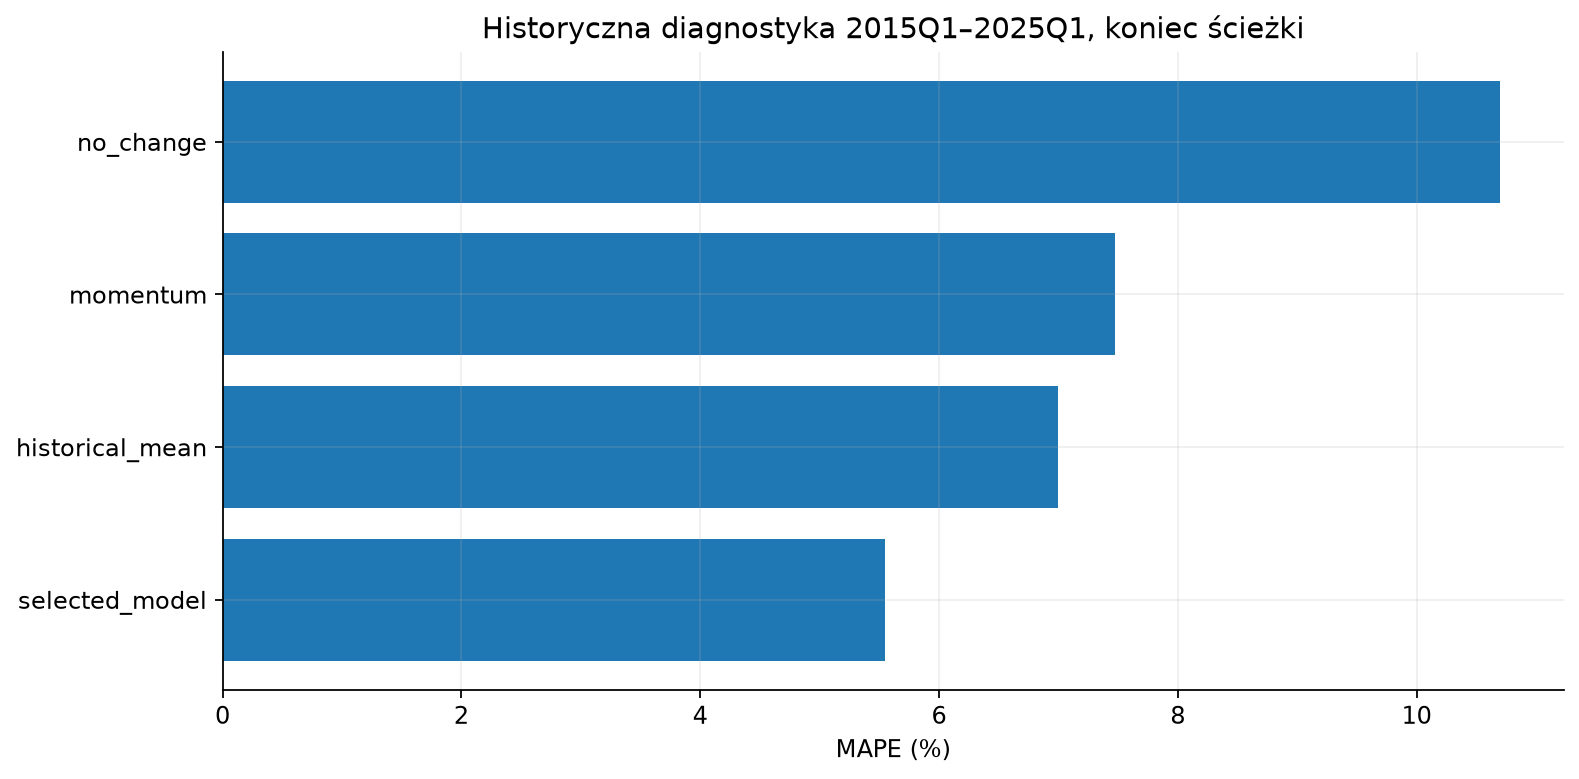

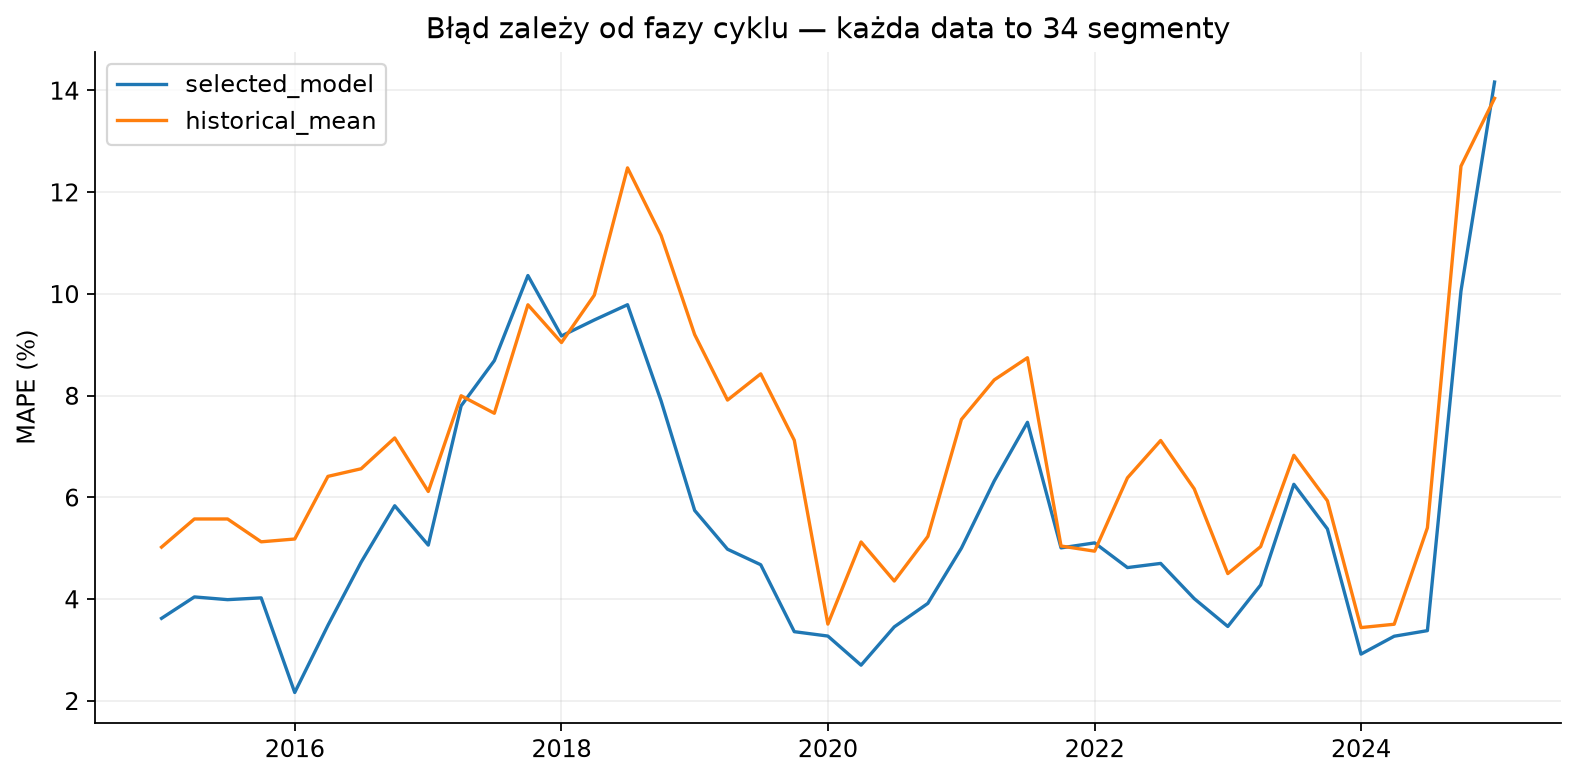

In [4]:
display(Image(filename=str(ROOT/'reports/figures/04_comparison.png')));display(Image(filename=str(ROOT/'reports/figures/05_stability.png')))

**Najważniejsze ograniczenie:** RF5,55%vs7,00%historycznie, ale13,76%vs3,88%dla utrzymania ostatniej ceny na2025Q2. Model ekstrapoluje wzrost z niedawnego okna i przeszacowuje w okresie wyhamowania. Nie ma podstaw do deklaracji stabilnej przewagi operacyjnej. Bootstrap opisuje historyczną różnicę błędów, nie niepewność przyszłej ceny.

,feature,delta_MAPE_pp,std
0,peer_yoy_known2,0.118401,0.072059
1,hedonic_yoy_known,0.050986,0.052800
2,local_yoy_known2,0.033104,0.035614
3,local_yoy_acceleration_known2,0.030879,0.027589
4,local_qoq_known2,0.013842,0.010655
5,hedonic_qoq_known,0.003963,0.012622
6,log_known_price,0.002742,0.001125
7,inflation_yoy_lag1,0.000000,0.000000
8,policy_rate_change4q_lag1,0.000000,0.000000
9,policy_rate_lag1,0.000000,0.000000


,feature,prediction,median_replaced_prediction
0,local_yoy_known2,15158.176808,15147.422874
1,local_qoq_known2,15158.176808,15138.937345
2,local_yoy_acceleration_known2,15158.176808,15077.281575
3,local_volatility4_known2,15158.176808,15151.071434
4,relative_price_known2,15158.176808,15166.084756


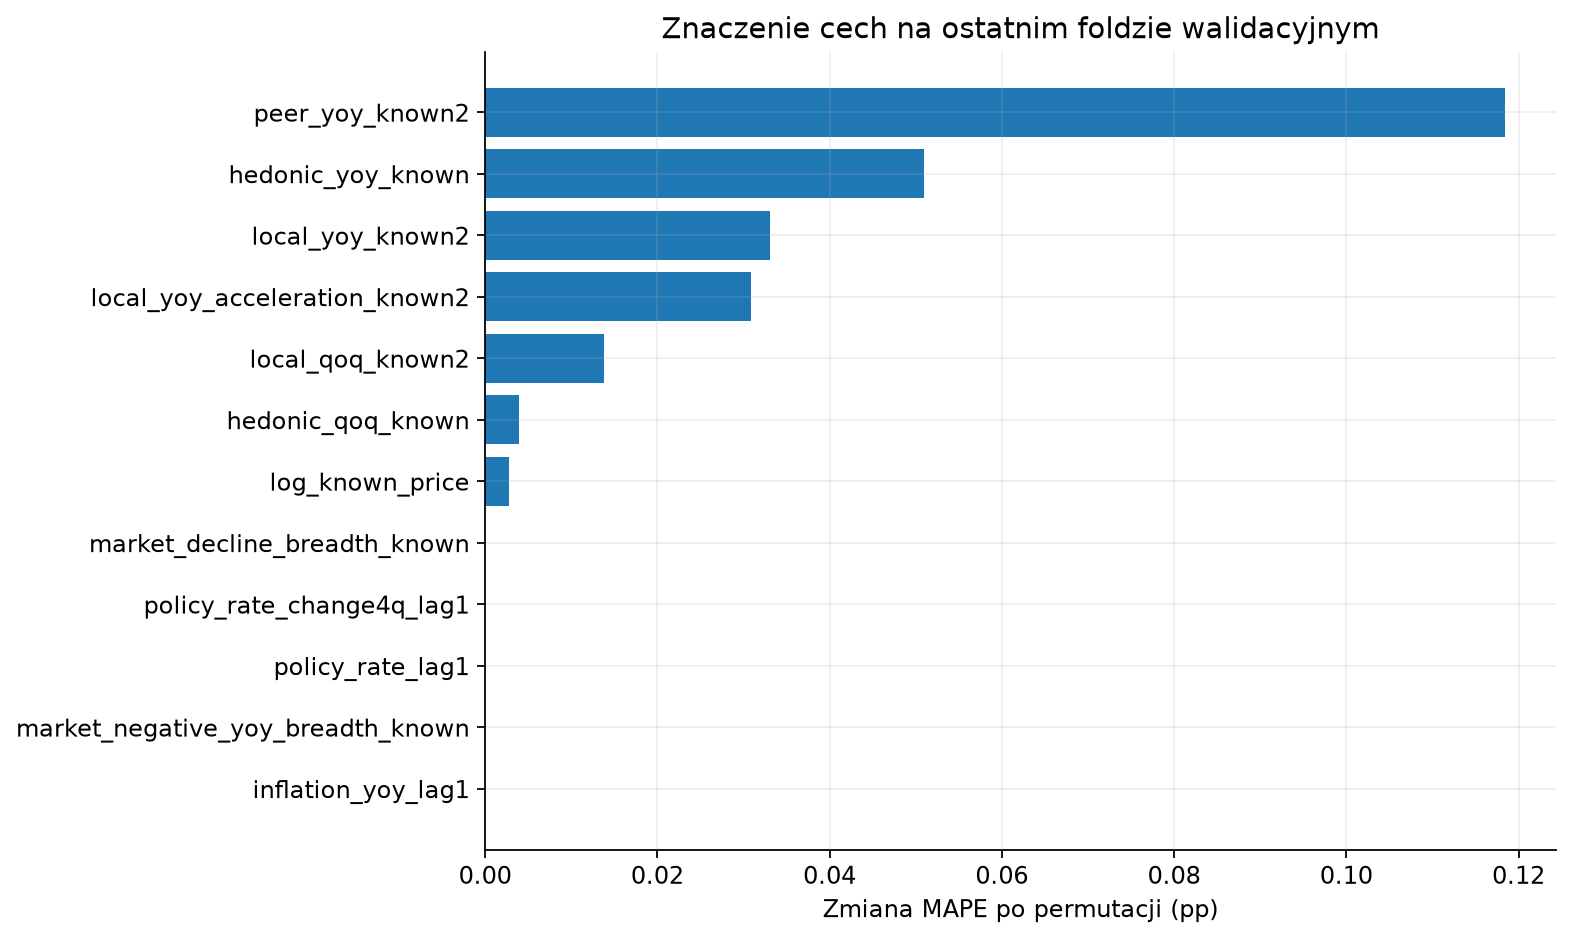

In [5]:
display(pd.read_csv(ROOT/'reports/tables/permutation_importance.csv'));display(pd.read_csv(ROOT/'reports/tables/local_sensitivity.csv').head());display(Image(filename=str(ROOT/'reports/figures/06_importance.png')))

Permutacja mierzy użyteczność predykcyjną przy współzależnych cechach. Analiza mediany jest lokalną wrażliwością, nie SHAP i nie przyczynowym efektem polityki pieniężnej.

In [6]:
from fastapi.testclient import TestClient
from api.app import app
client=TestClient(app)
response=client.post('/predict',json={'area':'Warszawa','market':'secondary'})
assert response.status_code==200
display(response.json())
print('Nieznane miasto:',client.post('/predict',json={'area':'Atlantyda','market':'secondary'}).status_code)

{'area': 'Warszawa',
 'market': 'secondary',
 'reference_origin': '2026Q3',
 'generated': '2026-11-15',
 'known_price_quarter': '2026Q1',
 'known_price_pln_m2': 16522.655483872208,
 'unit': 'PLN/m2',
 'scope': 'Średnia cena transakcyjna w mieście; archiwalny scenariusz badawczy',
 'forecasts': [{'horizon': 0,
   'target_quarter': '2026Q3',
   'prediction_pln_m2': 18068.25},
  {'horizon': 1, 'target_quarter': '2026Q4', 'prediction_pln_m2': 18916.44},
  {'horizon': 2, 'target_quarter': '2027Q1', 'prediction_pln_m2': 19608.27},
  {'horizon': 3, 'target_quarter': '2027Q2', 'prediction_pln_m2': 20081.73},
  {'horizon': 4, 'target_quarter': '2027Q3', 'prediction_pln_m2': 20266.87}],
 'warning': 'h0 to nowcast. Brak skalibrowanych przedziałów. To nie wycena mieszkania ani sygnał inwestycyjny.'}

Nieznane miasto: 422


In [7]:
display(json.loads((ROOT/'models/metadata.json').read_text()));display(json.loads((ROOT/'reports/tables/green_it.json').read_text()));display(json.loads((ROOT/'reports/tables/legacy_reproduction.json').read_text()))

{'model': 'multioutput log price path',
 'selected_trial': {'id': 'rf_12_d6',
  'algorithm': 'rf',
  'window': 12,
  'depth': 6,
  'leaf': 12,
  'trees': 120},
 'features': ['local_yoy_known2',
  'local_qoq_known2',
  'local_yoy_acceleration_known2',
  'local_volatility4_known2',
  'relative_price_known2',
  'primary_secondary_ratio_known2',
  'peer_yoy_known2',
  'log_known_price',
  'policy_rate_lag1',
  'policy_rate_change4q_lag1',
  'inflation_yoy_lag1',
  'national_wage_yoy_lag1',
  'national_mortgage_rate_lag1',
  'national_real_credit_flow_yoy_lag1',
  'national_sloos_demand_lag1',
  'national_sloos_easing_lag1',
  'market_decline_breadth_known',
  'market_negative_yoy_breadth_known',
  'hedonic_qoq_known',
  'hedonic_yoy_known',
  'credit_count_yoy_lag2',
  'credit_count_qoq_lag2',
  'credit_count_acceleration_lag2',
  'credit_count_t4_yoy_lag2'],
 'categoricals': ['area', 'market'],
 'horizons': [0, 1, 2, 3, 4],
 'reference_origin': '2026Q3',
 'build_date': '2026-11-15',
 'ref

{'production_train_seconds': 0.11457340000197291,
 'mean_historical_fit_seconds': 0.14399208293137392,
 'model_bytes': 456648,
 'threads': 2,
 'gpu': False,
 'carbon_emissions_measured': False}

{'rows': 34,
 'finite': True,
 'max_price_difference_pln_m2': 3.637978807091713e-12,
 'historical_h4_MAPE_pct': 5.600658563347869,
 'prediction_matrix_sha256': '9c9431c2841748d0b732a02bdc74d616a18779a60dedf8a9c03e90099acd4096',
 'note': 'Original estimator retained independently and its historical41origins reproduced; the new model is rebuilt from original provider files and tuned separately.'}

Zastosowanie: badawczy scenariusz średnich cen w miastach, porównanie benchmarków, wykrywanie okresów porażki modelu. Snapshot2026Q3wystawiono po kwartale odniesienia, więc nie jest to prawdziwy historyczny forecast issued-at-time. Nie wycenia konkretnego lokalu, nie ocenia płynności i nie podaje sygnału sprzedaży. Następny krok walidacyjny: nowe kwartały, bez strojenia pod ostatni test.